# 传统机器学习

逻辑回归 & 支持向量机

In [13]:
# 加载清理后的训练集和验证集
import pandas as pd

from sentiment_analysis.paths import CLEANED_DIR

train_data = pd.read_csv(CLEANED_DIR / "train.csv")
validation_data = pd.read_csv(CLEANED_DIR / "val.csv")

X_train = train_data["text"]
y_train = train_data["label"]

X_validation = validation_data["text"]
y_validation = validation_data["label"]

print(f"Train: {len(train_data):,}")
print(f"Validation: {len(validation_data):,}")

Train: 22,413
Validation: 2,491


In [14]:
# 加载不同 N-gram 下的 TF-IDF 参数
from sentiment_analysis.paths import TFIDF_DIR
import joblib

vectorizers = {
    name: joblib.load(TFIDF_DIR / f"{name}.joblib")
    for name in ["unigram", "bigram", "combined"]
}

for name, vectorizer in vectorizers.items():
    print(f"{name}: {len(vectorizer.vocabulary_):,} features")

unigram: 20,000 features
bigram: 20,000 features
combined: 20,000 features


In [15]:
feature_sets = {}

for name, vectorizer in vectorizers.items():
    feature_sets[name] = {
        "train": vectorizer.transform(X_train),
        "validation": vectorizer.transform(X_validation),
    }

    print(
        f"{name}: "
        f"Train {feature_sets[name]['train'].shape}, "
        f"Validation {feature_sets[name]['validation'].shape}"
    )

unigram: Train (22413, 20000), Validation (2491, 20000)
bigram: Train (22413, 20000), Validation (2491, 20000)
combined: Train (22413, 20000), Validation (2491, 20000)


## B01: Unigram + Logistic Regression

In [16]:
# 训练逻辑回归模型
from time import perf_counter

from sklearn.linear_model import LogisticRegression

X_train_unigram = feature_sets["unigram"]["train"]
X_validation_unigram = feature_sets["unigram"]["validation"]

logistic_regression_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
)

start = perf_counter()
logistic_regression_model.fit(X_train_unigram, y_train)
training_time = perf_counter() - start

print(f"Training time: {training_time:.2f} seconds")
print(f"Iterations: {logistic_regression_model.n_iter_[0]}")

Training time: 0.20 seconds
Iterations: 18


In [17]:
# 在验证集上评估模型
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_prediction = logistic_regression_model.predict(X_validation_unigram)

result = {
    "EXPERIMENT": "B01",
    "FEATURES": "Unigram",
    "MODEL": "Logistic Regression",
    "ACCURACY": accuracy_score(y_validation, y_prediction),
    "PRECISION": precision_score(y_validation, y_prediction),
    "RECALL": recall_score(y_validation, y_prediction),
    "F1": f1_score(y_validation, y_prediction),
}

display(pd.DataFrame([result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B01,Unigram,Logistic Regression,0.8824,0.8676,0.903,0.885


## 混淆矩阵

观察验证集中正面和负面评论的预测情况。

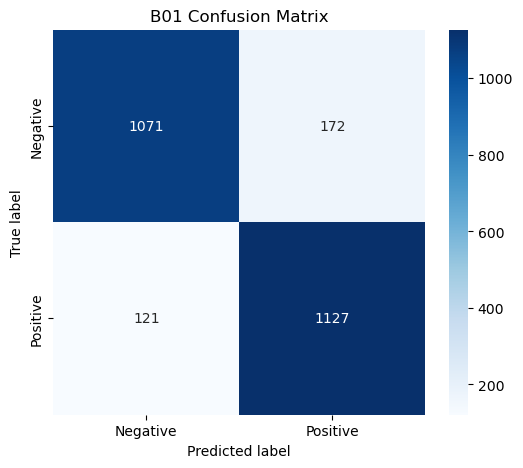

In [18]:
# 绘制混淆矩阵
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(y_validation, y_prediction, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("B01 Confusion Matrix")
plt.show()

## B02: Bigram + Logistic Regression

使用相同的模型参数，观察 Bigram 特征对分类结果的影响。

In [19]:
# 使用 Bigram 特征训练逻辑回归模型
X_train_bigram = feature_sets["bigram"]["train"]
X_validation_bigram = feature_sets["bigram"]["validation"]

bigram_logistic_regression_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
)

bigram_logistic_regression_model.fit(X_train_bigram, y_train)

print(f"Iterations: {bigram_logistic_regression_model.n_iter_[0]}")

Iterations: 30


In [20]:
# 在验证集上评估模型，与 B01 进行比较
y_prediction_bigram = bigram_logistic_regression_model.predict(X_validation_bigram)

bigram_result = {
    "EXPERIMENT": "B02",
    "FEATURES": "Bigram",
    "MODEL": "Logistic Regression",
    "ACCURACY": accuracy_score(y_validation, y_prediction_bigram),
    "PRECISION": precision_score(y_validation, y_prediction_bigram),
    "RECALL": recall_score(y_validation, y_prediction_bigram),
    "F1": f1_score(y_validation, y_prediction_bigram),
}

display(pd.DataFrame([result, bigram_result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B01,Unigram,Logistic Regression,0.8824,0.8676,0.9030,0.885
1,B02,Bigram,Logistic Regression,0.8675,0.8558,0.8846,0.870


## B03: Unigram + Bigram + Logistic Regression

使用相同的模型参数，观察组合特征对分类结果的影响。

In [21]:
# 使用组合特征训练逻辑回归模型
X_train_combined = feature_sets["combined"]["train"]
X_validation_combined = feature_sets["combined"]["validation"]

combined_logistic_regression_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
)

combined_logistic_regression_model.fit(X_train_combined, y_train)

print(f"Iterations: {combined_logistic_regression_model.n_iter_[0]}")

Iterations: 40


In [22]:
# 在验证集上评估模型，与前两组结果进行比较
y_prediction_combined = combined_logistic_regression_model.predict(X_validation_combined)

combined_result = {
    "EXPERIMENT": "B03",
    "FEATURES": "Unigram + Bigram",
    "MODEL": "Logistic Regression",
    "ACCURACY": accuracy_score(y_validation, y_prediction_combined),
    "PRECISION": precision_score(y_validation, y_prediction_combined),
    "RECALL": recall_score(y_validation, y_prediction_combined),
    "F1": f1_score(y_validation, y_prediction_combined),
}

display(pd.DataFrame([result, bigram_result, combined_result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B01,Unigram,Logistic Regression,0.8824,0.8676,0.9030,0.8850
1,B02,Bigram,Logistic Regression,0.8675,0.8558,0.8846,0.8700
2,B03,Unigram + Bigram,Logistic Regression,0.8828,0.8746,0.8942,0.8843


## B04: Unigram + Linear SVM

使用与 B01 相同的 Unigram 特征，比较两个分类模型的验证集表现。

In [23]:
# 使用 Unigram 特征训练线性支持向量机
from sklearn.svm import LinearSVC

unigram_svm_model = LinearSVC(
    C=1.0,
    max_iter=1000,
    random_state=42,
)

unigram_svm_model.fit(X_train_unigram, y_train)

print(f"Iterations: {unigram_svm_model.n_iter_}")

Iterations: 6


In [24]:
# 在验证集上评估模型，与 B01 进行比较
y_prediction_unigram_svm = unigram_svm_model.predict(X_validation_unigram)

unigram_svm_result = {
    "EXPERIMENT": "B04",
    "FEATURES": "Unigram",
    "MODEL": "Linear SVM",
    "ACCURACY": accuracy_score(y_validation, y_prediction_unigram_svm),
    "PRECISION": precision_score(y_validation, y_prediction_unigram_svm),
    "RECALL": recall_score(y_validation, y_prediction_unigram_svm),
    "F1": f1_score(y_validation, y_prediction_unigram_svm),
}

display(pd.DataFrame([result, unigram_svm_result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B01,Unigram,Logistic Regression,0.8824,0.8676,0.9030,0.8850
1,B04,Unigram,Linear SVM,0.8868,0.8768,0.9006,0.8885


## B05: Bigram + Linear SVM

In [25]:
# 使用 Bigram 特征训练线性支持向量机
bigram_svm_model = LinearSVC(
    C=1.0,
    max_iter=1000,
    random_state=42,
)

bigram_svm_model.fit(X_train_bigram, y_train)

print(f"Iterations: {bigram_svm_model.n_iter_}")

Iterations: 6


In [26]:
# 在验证集上评估模型
y_prediction_bigram_svm = bigram_svm_model.predict(X_validation_bigram)

bigram_svm_result = {
    "EXPERIMENT": "B05",
    "FEATURES": "Bigram",
    "MODEL": "Linear SVM",
    "ACCURACY": accuracy_score(y_validation, y_prediction_bigram_svm),
    "PRECISION": precision_score(y_validation, y_prediction_bigram_svm),
    "RECALL": recall_score(y_validation, y_prediction_bigram_svm),
    "F1": f1_score(y_validation, y_prediction_bigram_svm),
}

display(pd.DataFrame([bigram_result, bigram_svm_result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B02,Bigram,Logistic Regression,0.8675,0.8558,0.8846,0.8700
1,B05,Bigram,Linear SVM,0.8631,0.8574,0.8718,0.8645


## B06: Unigram + Bigram + Linear SVM

In [27]:
# 使用组合特征训练线性支持向量机
combined_svm_model = LinearSVC(
    C=1.0,
    max_iter=1000,
    random_state=42,
)

combined_svm_model.fit(X_train_combined, y_train)

print(f"Iterations: {combined_svm_model.n_iter_}")

Iterations: 6


In [28]:
# 在验证集上评估模型
y_prediction_combined_svm = combined_svm_model.predict(X_validation_combined)

combined_svm_result = {
    "EXPERIMENT": "B06",
    "FEATURES": "Unigram + Bigram",
    "MODEL": "Linear SVM",
    "ACCURACY": accuracy_score(y_validation, y_prediction_combined_svm),
    "PRECISION": precision_score(y_validation, y_prediction_combined_svm),
    "RECALL": recall_score(y_validation, y_prediction_combined_svm),
    "F1": f1_score(y_validation, y_prediction_combined_svm),
}

display(pd.DataFrame([combined_result, combined_svm_result]).round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B03,Unigram + Bigram,Logistic Regression,0.8828,0.8746,0.8942,0.8843
1,B06,Unigram + Bigram,Linear SVM,0.8876,0.8805,0.8974,0.8889


## 六组实验结果比较

In [29]:
# 汇总验证集结果
experiment_results = pd.DataFrame([
    result,
    bigram_result,
    combined_result,
    unigram_svm_result,
    bigram_svm_result,
    combined_svm_result,
])

display(experiment_results.round(4))

,EXPERIMENT,FEATURES,MODEL,ACCURACY,PRECISION,RECALL,F1
0,B01,Unigram,Logistic Regression,0.8824,0.8676,0.9030,0.8850
1,B02,Bigram,Logistic Regression,0.8675,0.8558,0.8846,0.8700
2,B03,Unigram + Bigram,Logistic Regression,0.8828,0.8746,0.8942,0.8843
3,B04,Unigram,Linear SVM,0.8868,0.8768,0.9006,0.8885
4,B05,Bigram,Linear SVM,0.8631,0.8574,0.8718,0.8645
5,B06,Unigram + Bigram,Linear SVM,0.8876,0.8805,0.8974,0.8889


## 验证集指标对比

比较不同特征和模型在验证集上的表现。

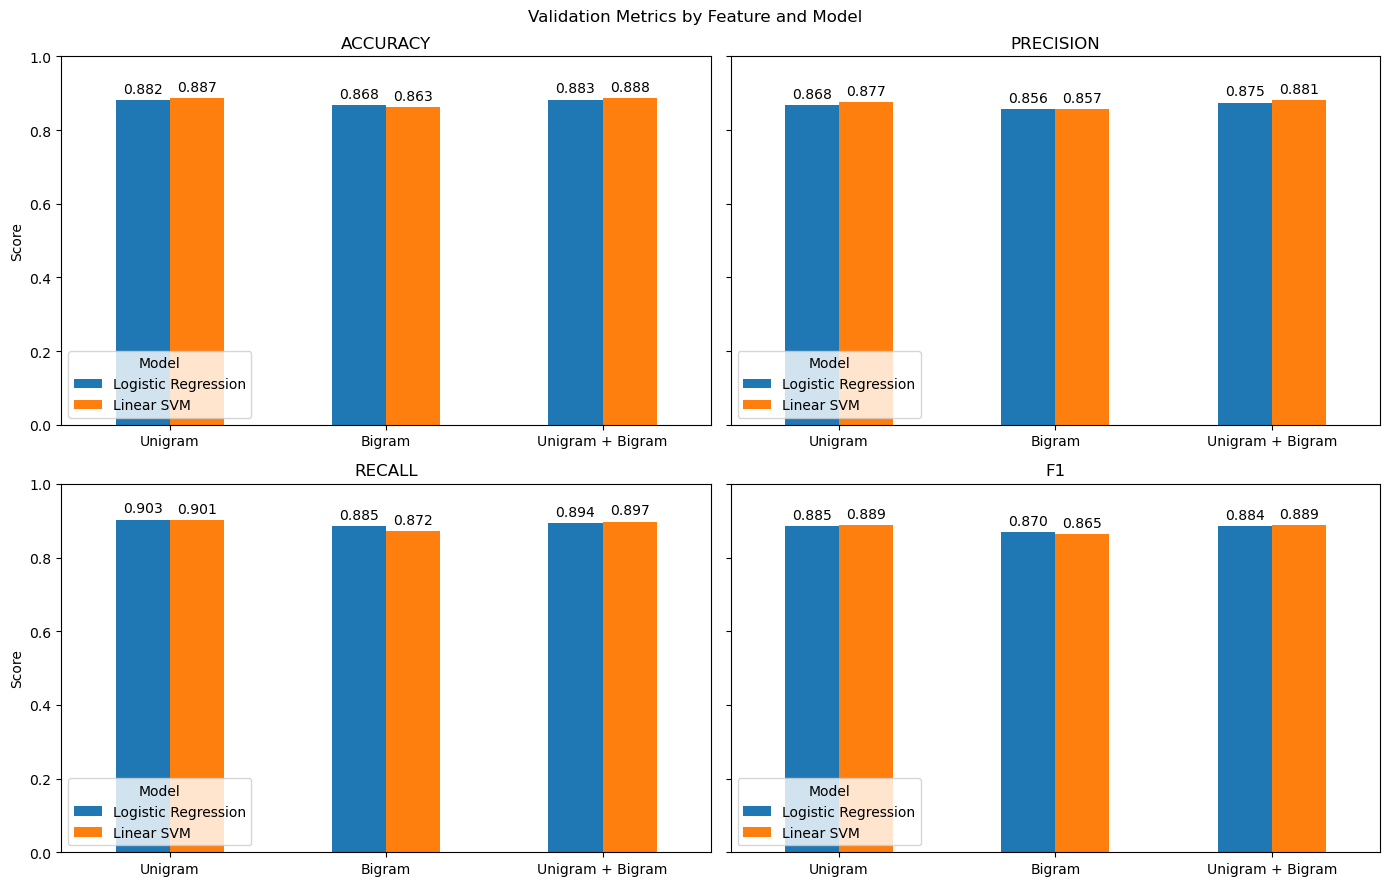

In [30]:
# 绘制六组实验的指标对比图
metrics = ["ACCURACY", "PRECISION", "RECALL", "F1"]
feature_order = ["Unigram", "Bigram", "Unigram + Bigram"]
model_order = ["Logistic Regression", "Linear SVM"]

figure, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

for metric, axis in zip(metrics, axes.flat):
    metric_results = experiment_results.pivot(
        index="FEATURES", columns="MODEL", values=metric,
    ).loc[feature_order, model_order]

    metric_results.plot(kind="bar", ax=axis, rot=0)
    axis.set_title(metric)
    axis.set_xlabel("")
    axis.set_ylabel("Score")
    axis.set_ylim(0, 1)
    axis.legend(title="Model")

    for bars in axis.containers:
        axis.bar_label(bars, fmt="%.3f", padding=3)

figure.suptitle("Validation Metrics by Feature and Model")
figure.tight_layout()

from sentiment_analysis.paths import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure.savefig(FIGURES_DIR / "traditional_ml_validation_metrics.png", dpi=150)
plt.show()

## 混淆矩阵与错误分析

比较 B01、B04 和 B06 在验证集上的预测，并查看部分预测不一致的评论。

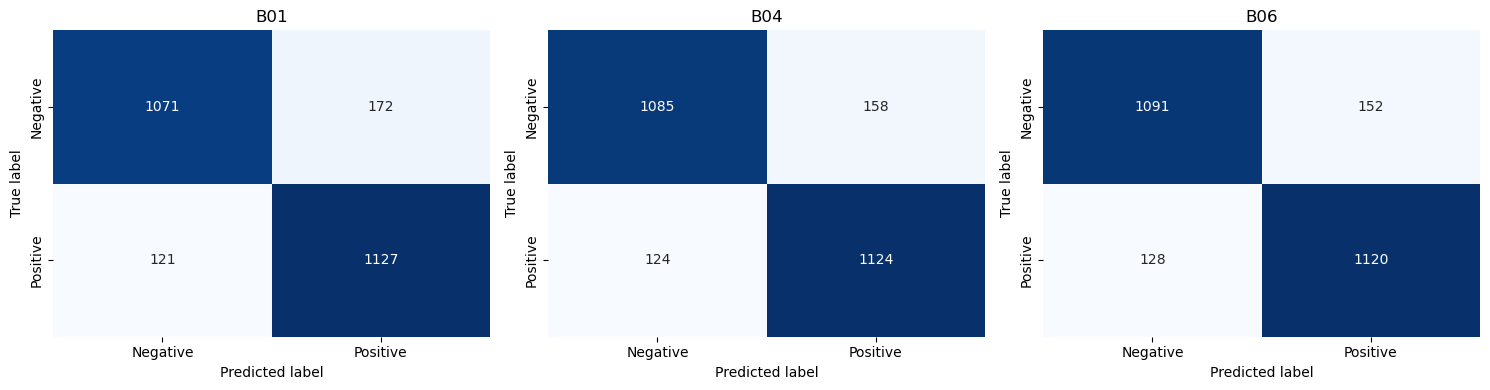

In [31]:
# 比较三个模型的混淆矩阵
predictions = {
    "B01": y_prediction,
    "B04": y_prediction_unigram_svm,
    "B06": y_prediction_combined_svm,
}

figure, axes = plt.subplots(1, 3, figsize=(15, 4))

for axis, (name, prediction) in zip(axes, predictions.items()):
    matrix = confusion_matrix(y_validation, prediction, labels=[0, 1])
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
    )
    axis.set_title(name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")

figure.tight_layout()

from sentiment_analysis.paths import FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
figure.savefig(FIGURES_DIR / "traditional_ml_confusion_matrices.png", dpi=150)
plt.show()

In [32]:
# 比较 B01 和 B06 的预测是否正确
prediction_comparison = validation_data[["text", "label"]].copy()
prediction_comparison["B01"] = y_prediction
prediction_comparison["B06"] = y_prediction_combined_svm

b01_correct = prediction_comparison["B01"] == prediction_comparison["label"]
b06_correct = prediction_comparison["B06"] == prediction_comparison["label"]

comparison_summary = pd.DataFrame([
    {"CASE": "Both correct", "COUNT": (b01_correct & b06_correct).sum()},
    {"CASE": "Only B01 correct", "COUNT": (b01_correct & ~b06_correct).sum()},
    {"CASE": "Only B06 correct", "COUNT": (~b01_correct & b06_correct).sum()},
    {"CASE": "Both wrong", "COUNT": (~b01_correct & ~b06_correct).sum()},
])

display(comparison_summary)

,CASE,COUNT
0,Both correct,2114
1,Only B01 correct,84
2,Only B06 correct,97
3,Both wrong,196


In [33]:
# 查看预测分歧的评论，分别展示每种情况的前三条
print("Only B01 correct:")
display(prediction_comparison[b01_correct & ~b06_correct].head(3))

print("Only B06 correct:")
display(prediction_comparison[~b01_correct & b06_correct].head(3))

Only B01 correct:


,text,label,B01,B06
11,Life is really too short for movies like this....,0,0,1
17,"A true anomaly in the French cinema ,this desp...",1,1,0
45,"There are laughs in this film, that is for sur...",0,0,1


Only B06 correct:


,text,label,B01,B06
2,The third Muppet movie is perhaps the most rel...,1,0,1
7,Always enjoy great films which deal with the s...,0,1,0
32,What happens when someone has so much social a...,1,0,1


In [35]:
# 查看两个模型都判断错误的评论
both_wrong = prediction_comparison[~b01_correct & ~b06_correct]

for index, row in both_wrong.head(3).iterrows():
    print(f"Index: {index} | True: {row['label']} | B01: {row['B01']} | B06: {row['B06']}")
    print(row["text"])
    print()

Index: 6 | True: 0 | B01: 1 | B06: 1
I will probably always go to see a Woody Alleb movie, as one never knows when he just might make a real return to his past greatness. Just one or two great moments or lines could make it worthwhile. sadly however this film just does'nt make it on any score. Saying thar actually makes me sad and even a little guilty. I'm sure my reaction is much like a lot of other fans of Woody, but what can one say? It's probably time for him to concentrate on his Clarinett, which in my opinion, he is rather quite good. Saying all of this, I'll still probably go to any new film Woody may come out with in the future. There's always hope and I'll continue to love and respect The WOODY!!

Index: 44 | True: 0 | B01: 1 | B06: 1
Storyline: The film spanning 4-odd hours covers in adequate details the happenings at the Kargil sector near the LOC in 1999 when the Pakistani infiltrators had crossed the LOC and had entered deep into the Indian territory and the Indian Retalia

前三条共同误判的样本中：

- Index 6 的标签为负面，评论一方面批评电影，另一方面表达对导演的喜爱和期待，包含不同方向的情绪。
- Index 44 的标签为负面，但正文多数内容似乎在称赞电影，仅末尾提到片长和歌曲的问题，值得进一步核对标签与评论。
- Index 53 的标签为正面，评论中包含针对不喜欢某类喜剧观众的否定表达，整体上则在推荐这部剧。

这些只是对少量样本的观察，不能据此确定模型误判的具体原因，也不能代表全部错误。

## B06 正则化参数比较

固定组合特征，在验证集上比较不同 C 值；测试集不参与参数选择。

In [34]:
# 比较不同 C 值下的 Linear SVM
c_values = [0.1, 1.0, 10.0]
c_results = []

for c_value in c_values:
    svm_model = LinearSVC(C=c_value, max_iter=1000, random_state=42)
    svm_model.fit(X_train_combined, y_train)
    y_prediction_c = svm_model.predict(X_validation_combined)

    c_results.append({
        "C": c_value,
        "ACCURACY": accuracy_score(y_validation, y_prediction_c),
        "PRECISION": precision_score(y_validation, y_prediction_c),
        "RECALL": recall_score(y_validation, y_prediction_c),
        "F1": f1_score(y_validation, y_prediction_c),
        "ITERATIONS": svm_model.n_iter_,
    })

c_comparison = pd.DataFrame(c_results)
display(c_comparison.round(4))

,C,ACCURACY,PRECISION,RECALL,F1,ITERATIONS
0,0.1,0.8864,0.8767,0.8998,0.8881,5
1,1.0,0.8876,0.8805,0.8974,0.8889,6
2,10.0,0.8727,0.8651,0.8838,0.8744,9


## 实验结论

在当前数据划分、20,000 个特征和默认基线参数下：

- 两种模型单独使用 Bigram 的验证集 F1 均低于使用 Unigram 或组合特征。
- B06 的验证集 Accuracy 和 F1 在六组中最高，B04 与其接近；B01 的 Recall 最高。差异较小，不应据此断定模型普遍更优。
- B01 与 B06 各自正确而对方错误的样本分别为 84 和 97 条，说明两者的错误并不完全重合。
- 在 B06 比较的 C 值中，1.0 的验证集 F1 最高，与 0.1 接近，10.0 较低。

B06（C=1.0）暂作为传统机器学习代表。以上结果用于探索和模型选择，测试集留到最终评估。

In [ ]:
# 保存实验结果表
from sentiment_analysis.paths import TABLES_DIR

TABLES_DIR.mkdir(parents=True, exist_ok=True)
experiment_results.to_csv(TABLES_DIR / "traditional_ml_validation_metrics.csv", index=False)
comparison_summary.to_csv(TABLES_DIR / "traditional_ml_prediction_comparison.csv", index=False)
c_comparison.to_csv(TABLES_DIR / "traditional_ml_svm_c_comparison.csv", index=False)

print(f"Results saved to: {TABLES_DIR}")